# 10: Final Model Comparison (Task 4)

Compare logistic regression (04), gradient boosting (05), and random forest (06) side by side and choose a model to carry forward. This notebook combines Valerie Weiner's model evaluation (`07_model_evaluation.ipynb`: baseline comparison, confusion matrices, limitations) with Ansa Kanwal's success metrics (`08_success_metrics.ipynb`: probability quality, calibration, bootstrap intervals, SHAP), and adds ROC/PR curves, a threshold trade-off, and a subgroup check.

**Inputs:**
- `outputs/task3/*.csv`, written by `08_success_metrics.ipynb` (test-set predictions, metrics, calibration bins, bootstrap intervals, SHAP importance)
- `data/processed/model_dataset_2025.csv` and its spec, for the demographic columns used in the subgroup check

**Output:** the calibration and subgroup charts are also saved to `outputs/task4/figures/` for the README.

No model is refit here, so this notebook runs in seconds and always matches 08. If a model is re-tuned, rerun 08 first.

All metrics use `weight_pop`, classification metrics use a 0.5 threshold, and the positive class (1) is **financially fragile**: the respondent could not cover a $400 emergency expense with cash or its equivalent.

## Key results

All numbers come from the held-out 2025 test set (2,587 respondents), weighted to the U.S. adult population.

- **All three models are far better than guessing.** Accuracy is 85 to 86% vs 63% for always predicting "not fragile", and ROC AUC is 0.92 to 0.93 vs 0.50.
- **Gradient boosting and logistic regression are tied.** Gradient boosting is slightly ahead on every metric (ROC AUC 0.928 vs 0.925, Brier 0.100 vs 0.103, 202 vs 210 missed fragile respondents), but the bootstrap intervals for the differences include zero.
- **Random forest is reliably the weakest**: lowest ROC AUC (0.919), worst Brier (0.111), the most missed fragile respondents (227), and the worst calibration (ECE 0.049 vs 0.015 to 0.019).
- **About 1 in 5 fragile respondents is missed at the 0.5 threshold.** Lowering the threshold to 0.4 catches about 84% instead of 78 to 79%, at the cost of more false alarms.
- **All three models are weaker for some groups.** Ranking is worse for Black respondents (ROC AUC 0.85 vs 0.92 to 0.93 for White respondents), their risk is understated, and fragile respondents in higher-income and older groups are often missed. The pattern is shared by all three models.
- **Recommendation: logistic regression**, with gradient boosting as a cross-check. It performs as well as the best model, is the best calibrated, can be explained directly through its coefficients, and relies least on race and ethnicity and on the emergency-savings questions. See section 8.

## 1. Imports and data

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
    precision_recall_curve, precision_score, recall_score,
    roc_auc_score, roc_curve, brier_score_loss,
)

THRESHOLD = 0.5
MODELS = ["Logistic regression", "Gradient boosting", "Random forest"]
SLUG = {"Logistic regression": "lr", "Gradient boosting": "gb", "Random forest": "rf"}
COLORS = {"Logistic regression": "tab:blue", "Gradient boosting": "tab:green",
          "Random forest": "tab:orange"}

ROOT = Path("..") if Path("../data/processed").exists() else Path(".")
TASK3 = ROOT / "outputs/task3"
FIGURES = ROOT / "outputs/task4/figures"  # charts used in the README
FIGURES.mkdir(parents=True, exist_ok=True)

data = pd.read_csv(ROOT / "data/processed/model_dataset_2025.csv", low_memory=False)
with open(ROOT / "data/processed/model_dataset_2025_spec.json", encoding="utf-8") as f:
    spec = json.load(f)
ID, TARGET = spec["id"], spec["target"]["column"]

predictions = pd.read_csv(TASK3 / "test_predictions.csv")
metrics = pd.read_csv(TASK3 / "metrics.csv")
calibration_bins = pd.read_csv(TASK3 / "calibration_bins.csv")
intervals = pd.read_csv(TASK3 / "bootstrap_intervals.csv")
paired = pd.read_csv(TASK3 / "bootstrap_paired_differences.csv")
shap_importance = pd.read_csv(TASK3 / "shap_importance.csv")

# Attach demographics for the subgroup check, keeping 08's row order.
test = predictions.merge(data.loc[data["split"] == "test", [ID, TARGET] + spec["protected_attributes"]
                                  + ["inc_4cat_50k"]], on=ID, how="left", validate="1:1")
assert len(test) == len(predictions) == (data["split"] == "test").sum()
assert (test["actual_fragile"] == test[TARGET]).all()
# The en dash in the income labels is garbled in the source file.
test["inc_4cat_50k"] = test["inc_4cat_50k"].str.replace("�", "-")

y, w = test["actual_fragile"].to_numpy(), test["weight_pop"].to_numpy()
p = {name: test[f"p_{SLUG[name]}"].to_numpy() for name in MODELS}

# The saved predictions must reproduce 08's metric table.
for name in MODELS:
    saved = metrics.set_index(["model", "features"]).loc[(name, "with EF"), "ROC AUC"]
    assert abs(roc_auc_score(y, p[name], sample_weight=w) - saved) < 1e-9
print(f"Test set: {len(test):,} respondents; weighted fragility rate {np.average(y, weights=w):.1%}")

Test set: 2,587 respondents; weighted fragility rate 37.0%


## 2. Overall comparison

Two baselines: the **majority class** from 07 (always predicts "not fragile", the more common answer) and the **training prevalence** from 08 (gives everyone the 37% average probability). Brackets are bootstrap 95% intervals from 08.

In [2]:
train = data[data["split"] == "train"]
majority = int(np.average(train[TARGET], weights=train["weight_pop"]) >= 0.5)
majority_pred = np.full(len(y), majority)
majority_row = {
    "model": "Majority class (07)", "ROC AUC": 0.5,
    "Brier": brier_score_loss(y, majority_pred, sample_weight=w),
    "Accuracy": accuracy_score(y, majority_pred, sample_weight=w),
    "Precision": precision_score(y, majority_pred, sample_weight=w, zero_division=0),
    "Recall": recall_score(y, majority_pred, sample_weight=w),
}

with_ef = metrics[metrics["features"].isin(["with EF", "none"])].set_index("model")
with_ef = with_ef.rename(index={"Training prevalence": "Training prevalence (08)"})
table = pd.concat([pd.DataFrame([majority_row]).set_index("model"),
                   with_ef.drop(columns="features")])

def with_interval(metric):
    out = table[metric].map("{:.3f}".format)
    for _, row in intervals[intervals["metric"] == metric].iterrows():
        out[row["model"]] = f"{row['estimate']:.3f} [{row['lower']:.3f}, {row['upper']:.3f}]"
    return out

summary = pd.DataFrame({
    "ROC AUC": with_interval("ROC AUC"),
    "PR AUC": table["PR AUC"].map(lambda v: "" if pd.isna(v) else f"{v:.3f}"),
    "Brier": with_interval("Brier"),
    "ECE": with_interval("ECE").where(table["ECE"].notna(), ""),
    "Accuracy": table["Accuracy"].map("{:.1%}".format),
    "Precision": table["Precision"].map("{:.1%}".format),
    "Recall": table["Recall"].map("{:.1%}".format),
    "F1": table["F1"].map(lambda v: "" if pd.isna(v) else f"{v:.3f}"),
})
display(summary)

,ROC AUC,PR AUC,Brier,ECE,Accuracy,Precision,Recall,F1
model,,,,,,,,
Majority class (07),0.500,,0.370,,63.0%,0.0%,0.0%,
Training prevalence (08),0.500,0.370,0.233,0.002,63.0%,0.0%,0.0%,0.000
Logistic regression,"0.925 [0.914, 0.937]",0.875,"0.103 [0.094, 0.111]","0.015 [0.013, 0.033]",85.6%,82.1%,78.0%,0.800
Gradient boosting,"0.928 [0.918, 0.939]",0.880,"0.100 [0.092, 0.108]","0.019 [0.015, 0.035]",86.2%,82.9%,79.2%,0.810
Random forest,"0.919 [0.907, 0.931]",0.869,"0.111 [0.104, 0.118]","0.049 [0.039, 0.063]",85.1%,81.9%,76.7%,0.792


**Are the differences real?** Paired bootstrap differences from 08 (same resampled respondents for both models). An interval that excludes zero means the gap is larger than test-set noise.

In [3]:
display(paired.set_index(["metric", "comparison"]).round(3))

,,lower,upper,share of draws > 0
metric,comparison,,,
ROC AUC,Gradient boosting - Logistic regression,-0.001,0.006,0.930
Brier,Gradient boosting - Logistic regression,-0.005,0.001,0.070
ECE,Gradient boosting - Logistic regression,-0.010,0.015,0.646
ROC AUC,Gradient boosting - Random forest,0.005,0.014,1.000
Brier,Gradient boosting - Random forest,-0.015,-0.007,0.000
ECE,Gradient boosting - Random forest,-0.043,-0.008,0.000
ROC AUC,Logistic regression - Random forest,0.002,0.011,0.998
Brier,Logistic regression - Random forest,-0.013,-0.005,0.000
ECE,Logistic regression - Random forest,-0.043,-0.012,0.000


### ROC and precision-recall curves

The ROC curve shows how many fragile respondents are caught (true positive rate) for each false-alarm rate as the threshold moves. The precision-recall curve focuses on the fragile group: how precise the flags stay as more fragile respondents are caught. Dots mark the 0.5 threshold.

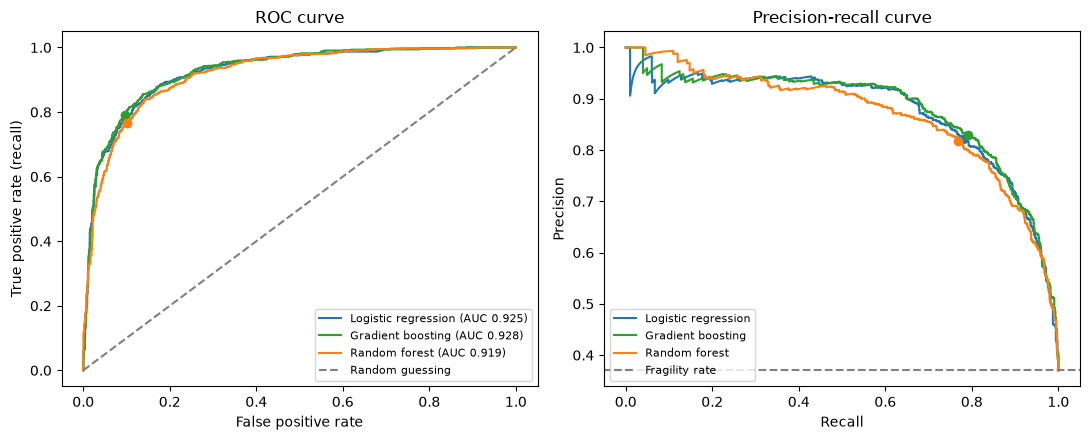

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name in MODELS:
    fpr, tpr, roc_thr = roc_curve(y, p[name], sample_weight=w)
    auc = roc_auc_score(y, p[name], sample_weight=w)
    axes[0].plot(fpr, tpr, color=COLORS[name], label=f"{name} (AUC {auc:.3f})")
    i = np.argmin(np.abs(roc_thr - THRESHOLD))
    axes[0].plot(fpr[i], tpr[i], "o", color=COLORS[name])

    precision, recall, pr_thr = precision_recall_curve(y, p[name], sample_weight=w)
    axes[1].plot(recall, precision, color=COLORS[name], label=name)
    i = np.argmin(np.abs(pr_thr - THRESHOLD))
    axes[1].plot(recall[i], precision[i], "o", color=COLORS[name])

axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Random guessing")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate (recall)", title="ROC curve")
axes[1].axhline(np.average(y, weights=w), linestyle="--", color="gray", label="Fragility rate")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve")
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "lower left", fontsize=8)
fig.tight_layout()
plt.show()

## 3. Confusion matrices

Extends 07's logistic-regression confusion matrix to all three models. The top row counts respondents; the bottom row shows shares of the weighted test population (all four cells add to 100%), as in 07.

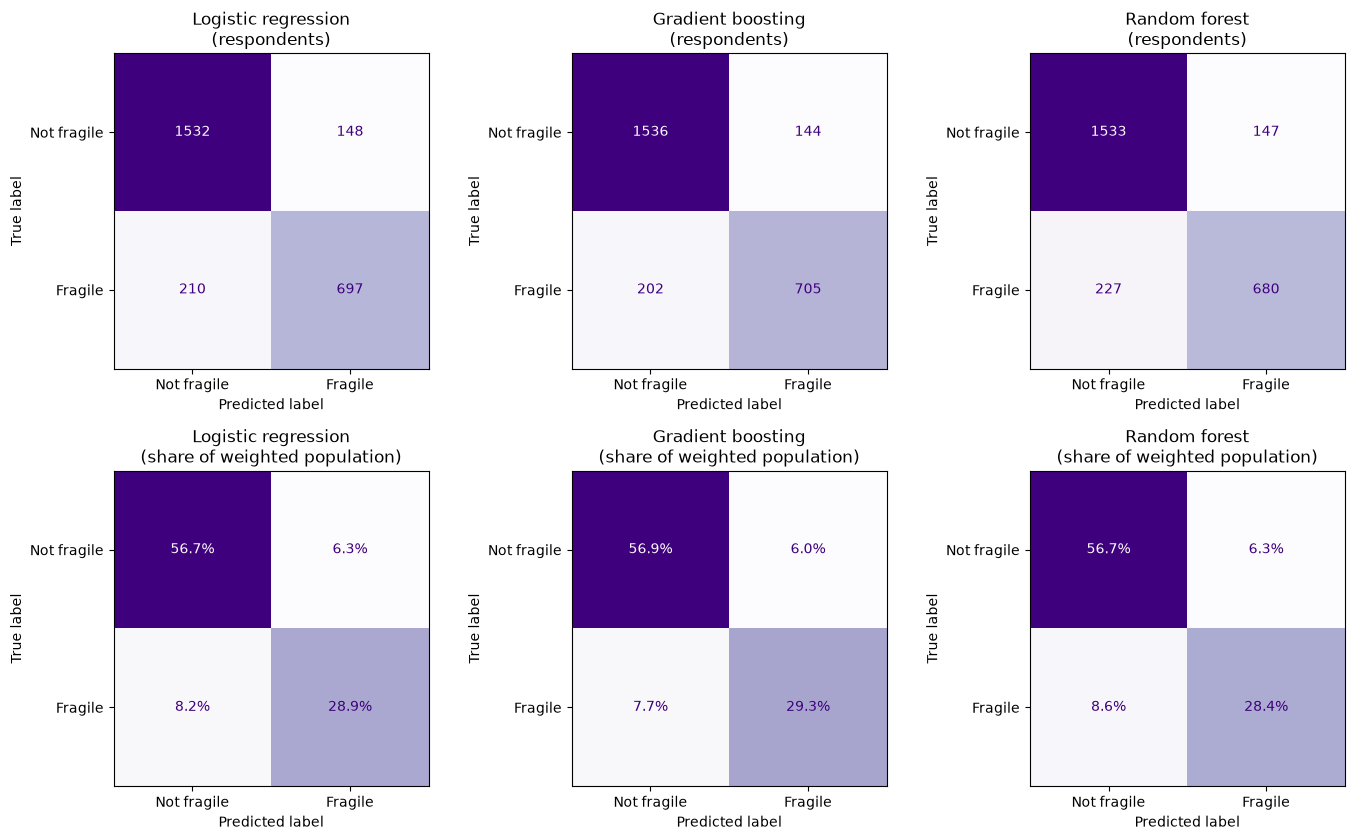

,correct,false alarms (FP),missed fragile (FN),weighted correct,weighted FP,weighted FN
model,,,,,,
Logistic regression,2229,148,210,85.6%,6.3%,8.2%
Gradient boosting,2241,144,202,86.2%,6.0%,7.7%
Random forest,2213,147,227,85.1%,6.3%,8.6%


In [5]:
LABELS = ["Not fragile", "Fragile"]
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))
error_rows = []
for col, name in enumerate(MODELS):
    predicted = (p[name] >= THRESHOLD).astype(int)
    counts = confusion_matrix(y, predicted, labels=[0, 1])
    shares = confusion_matrix(y, predicted, labels=[0, 1], sample_weight=w, normalize="all")
    ConfusionMatrixDisplay(counts, display_labels=LABELS).plot(
        ax=axes[0, col], cmap="Purples", values_format="d", colorbar=False)
    ConfusionMatrixDisplay(shares, display_labels=LABELS).plot(
        ax=axes[1, col], cmap="Purples", values_format=".1%", colorbar=False)
    axes[0, col].set_title(f"{name}\n(respondents)")
    axes[1, col].set_title(f"{name}\n(share of weighted population)")
    (tn, fp), (fn, tp) = counts
    (wtn, wfp), (wfn, wtp) = shares
    error_rows.append({
        "model": name, "correct": tn + tp, "false alarms (FP)": fp, "missed fragile (FN)": fn,
        "weighted correct": wtn + wtp, "weighted FP": wfp, "weighted FN": wfn,
    })
fig.tight_layout()
plt.show()

errors = pd.DataFrame(error_rows).set_index("model")
display(errors.style.format({c: "{:.1%}" for c in ["weighted correct", "weighted FP", "weighted FN"]}))

**Reading the confusion matrices.** The three models make almost the same errors. At the 0.5 threshold:

- **Logistic regression** misses 210 fragile respondents and wrongly flags 148, as reported in 07.
- **Gradient boosting** misses 202 and wrongly flags 144.
- **Random forest** misses 227 and wrongly flags 147, so its extra errors are almost all missed fragile respondents.

After weighting, about 86% of the population is classified correctly by each model. Missed fragile respondents (7.7 to 8.6%) outnumber false alarms (6.0 to 6.3%) for all three. As 07 pointed out, these are shares of the whole population, not error rates within each class: of the people who really are fragile, roughly one in five is missed.

### Threshold trade-off

Precision, recall, and accuracy above all depend on the 0.5 threshold (a limitation noted in 07). Lowering the threshold catches more fragile respondents at the cost of more false alarms. The chart shows that trade-off for each model.

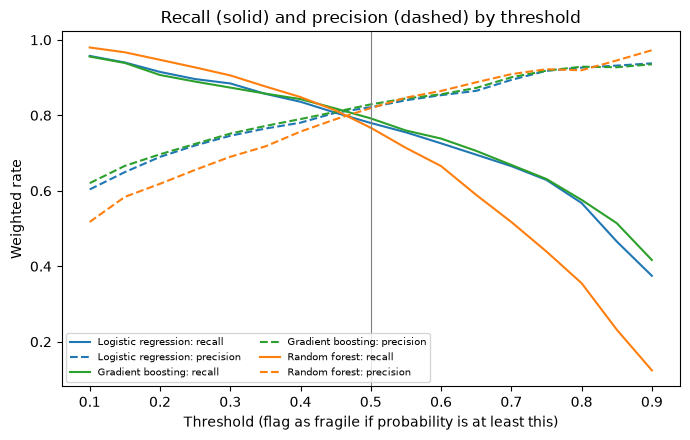

recall                                    \
model     Gradient boosting Logistic regression Random forest   
threshold                                                       
0.3                   0.873               0.885         0.906   
0.4                   0.843               0.836         0.848   
0.5                   0.792               0.780         0.767   
0.6                   0.738               0.726         0.665   

                  precision                                    
model     Gradient boosting Logistic regression Random forest  
threshold                                                      
0.3                   0.752               0.746         0.690  
0.4                   0.790               0.781         0.757  
0.5                   0.829               0.821         0.819  
0.6                   0.856               0.853         0.865

In [6]:
thresholds = np.round(np.arange(0.1, 0.91, 0.05), 2)
rows = []
for name in MODELS:
    for t in thresholds:
        predicted = (p[name] >= t).astype(int)
        rows.append({"model": name, "threshold": t,
                     "recall": recall_score(y, predicted, sample_weight=w),
                     "precision": precision_score(y, predicted, sample_weight=w, zero_division=0)})
tradeoff = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 4.5))
for name in MODELS:
    rows = tradeoff[tradeoff["model"] == name]
    ax.plot(rows["threshold"], rows["recall"], color=COLORS[name], label=f"{name}: recall")
    ax.plot(rows["threshold"], rows["precision"], "--", color=COLORS[name], label=f"{name}: precision")
ax.axvline(THRESHOLD, color="gray", linewidth=0.8)
ax.set(xlabel="Threshold (flag as fragile if probability is at least this)", ylabel="Weighted rate",
       title="Recall (solid) and precision (dashed) by threshold")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

display(tradeoff[tradeoff["threshold"].isin([0.3, 0.4, 0.5, 0.6])]
        .pivot(index="threshold", columns="model", values=["recall", "precision"]).round(3))

## 4. Calibration

From 08. If a model is well calibrated, respondents given a 30% probability are fragile about 30% of the time, so its points sit on the diagonal. ECE is the weighted average gap.

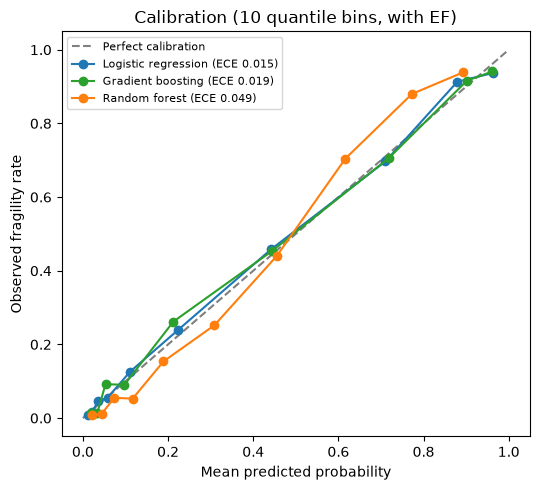

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
for name in MODELS:
    bins = calibration_bins[(calibration_bins["model"] == name)
                            & (calibration_bins["features"] == "with EF")]
    ece = metrics.set_index(["model", "features"]).loc[(name, "with EF"), "ECE"]
    ax.plot(bins["mean_predicted"], bins["observed_rate"], "o-", color=COLORS[name],
            label=f"{name} (ECE {ece:.3f})")
ax.set(xlabel="Mean predicted probability", ylabel="Observed fragility rate",
       title="Calibration (10 quantile bins, with EF)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "calibration.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. With vs without the emergency-savings (EF) questions

The 16 EF questions are close to the target (see 03). Each model was refit without them in 08 to check that it is not just repeating those answers.

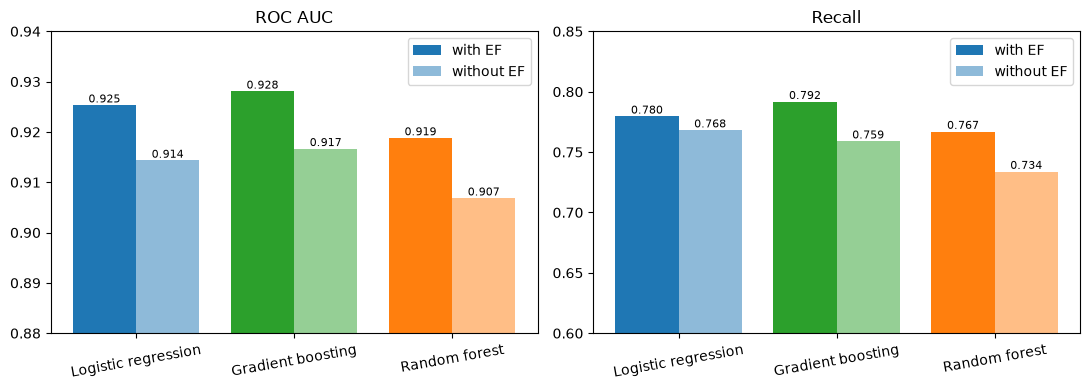

,ROC AUC,PR AUC,Brier,ECE,Recall
model,,,,,
Logistic regression,-0.011,-0.020,0.010,0.001,-0.011
Gradient boosting,-0.011,-0.024,0.011,-0.003,-0.033
Random forest,-0.012,-0.021,0.010,0.008,-0.033


In [8]:
by_features = metrics[metrics["features"] != "none"].pivot(index="model", columns="features")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, ylim in [(axes[0], "ROC AUC", (0.88, 0.94)), (axes[1], "Recall", (0.6, 0.85))]:
    values = by_features[metric].loc[MODELS]
    x = np.arange(len(MODELS))
    for offset, label, alpha in [(-0.2, "with EF", 1.0), (0.2, "without EF", 0.5)]:
        bars = ax.bar(x + offset, values[label], width=0.4, alpha=alpha, label=label,
                      color=[COLORS[m] for m in MODELS])
        ax.bar_label(bars, fmt="%.3f", fontsize=8)
    ax.set_xticks(x, MODELS, rotation=10)
    ax.set(ylim=ylim, title=metric)
    ax.legend()
fig.tight_layout()
plt.show()

display((by_features.xs("without EF", axis=1, level=1) - by_features.xs("with EF", axis=1, level=1))
        [["ROC AUC", "PR AUC", "Brier", "ECE", "Recall"]].loc[MODELS].round(3))

## 6. Subgroup check

07 noted that overall metrics can hide differences between demographic groups. Here each model is scored separately within race and ethnicity, gender, age, and income groups. **Calibration gap** is mean predicted probability minus observed fragility rate: positive means the model overstates the group's risk, negative means it understates it.

Groups are scored on few respondents (the smallest has 64), so differences of a few points can be noise. This is a screening check, not a fairness audit.

In [9]:
GROUPS = {"race_5cat": "Race / ethnicity", "ppgender": "Gender",
          "ppagecat": "Age", "inc_4cat_50k": "Income"}
subgroup_rows = []
for column, title in GROUPS.items():
    for group, rows in test.groupby(column):
        yg, wg = rows["actual_fragile"], rows["weight_pop"]
        for name in MODELS:
            pg = rows[f"p_{SLUG[name]}"]
            subgroup_rows.append({
                "attribute": title, "group": group, "model": name, "respondents": len(rows),
                "fragile rate": np.average(yg, weights=wg),
                "ROC AUC": roc_auc_score(yg, pg, sample_weight=wg),
                "recall": recall_score(yg, pg >= THRESHOLD, sample_weight=wg),
                "calibration gap": np.average(pg, weights=wg) - np.average(yg, weights=wg),
            })
subgroups = pd.DataFrame(subgroup_rows)

wide = subgroups.pivot_table(index=["attribute", "group", "respondents", "fragile rate"],
                             columns="model", values=["ROC AUC", "recall", "calibration gap"])
wide = wide.reindex(columns=MODELS, level="model")
display(wide.round(3))

ROC AUC  \
model                                                       Logistic regression   
attribute        group             respondents fragile rate                       
Age              18-24             208         0.566114                   0.883   
                 25-34             355         0.480430                   0.932   
                 35-44             435         0.474108                   0.903   
                 45-54             364         0.349511                   0.942   
                 55-64             492         0.280970                   0.924   
                 65-74             444         0.216381                   0.911   
                 75+               289         0.168250                   0.913   
Gender           Female            1272        0.390598                   0.931   
                 Male              1315        0.349701                   0.919   
Income           $100,000 or more  1039        0.172978                   0.901   
                 $25,000–$49,999   413         0.554267                   0.892   
                 $50,000–$99,999   674         0.356477                   0.917   
                 Less than $25,000 461         0.687569                   0.897   
Race / ethnicity Asian             142         0.236418                   0.916   
                 Black             319         0.632697                   0.853   
                 Hispanic          339         0.504954                   0.928   
                 Other             64          0.686169                   0.867   
                 White             1723        0.276533                   0.923   

                                                                               \
model                                                       Gradient boosting   
attribute        group             respondents fragile rate                     
Age              18-24             208         0.566114                 0.891   
                 25-34             355         0.480430                 0.939   
                 35-44             435         0.474108                 0.904   
                 45-54             364         0.349511                 0.944   
                 55-64             492         0.280970                 0.925   
                 65-74             444         0.216381                 0.920   
                 75+               289         0.168250                 0.912   
Gender           Female            1272        0.390598                 0.934   
                 Male              1315        0.349701                 0.921   
Income           $100,000 or more  1039        0.172978                 0.907   
                 $25,000–$49,999   413         0.554267                 0.891   
                 $50,000–$99,999   674         0.356477                 0.919   
                 Less than $25,000 461         0.687569                 0.898   
Race / ethnicity Asian             142         0.236418                 0.922   
                 Black             319         0.632697                 0.852   
                 Hispanic          339         0.504954                 0.925   
                 Other             64          0.686169                 0.850   
                 White             1723        0.276533                 0.929   

                                                                           \
model                                                       Random forest   
attribute        group             respondents fragile rate                 
Age              18-24             208         0.566114             0.843   
                 25-34             355         0.480430             0.933   
                 35-44             435         0.474108             0.905   
                 45-54             364         0.349511             0.932   
                 55-64             492         0.280970             0.916   
          

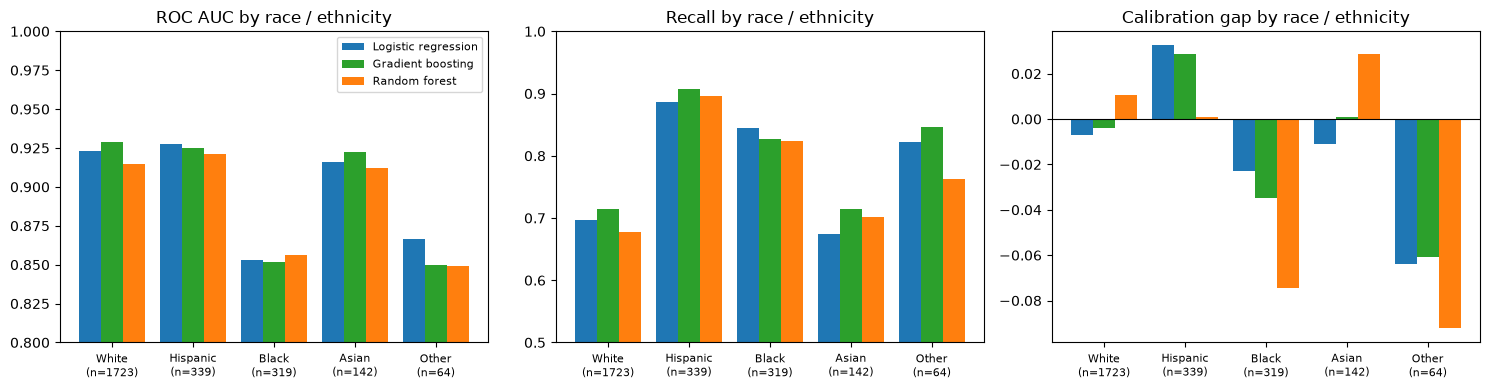

In [10]:
race = subgroups[subgroups["attribute"] == "Race / ethnicity"]
groups = race.drop_duplicates("group").sort_values("respondents", ascending=False)
labels = [f"{g}\n(n={n})" for g, n in zip(groups["group"], groups["respondents"])]
x = np.arange(len(groups))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["ROC AUC", "recall", "calibration gap"]):
    for i, name in enumerate(MODELS):
        values = race[race["model"] == name].set_index("group").loc[groups["group"], metric]
        ax.bar(x + (i - 1) * 0.27, values, width=0.27, color=COLORS[name], label=name)
    ax.set_xticks(x, labels, fontsize=8)
    ax.set_title(f"{metric[0].upper() + metric[1:]} by race / ethnicity")
    if metric == "calibration gap":
        ax.axhline(0, color="black", linewidth=0.8)
    else:
        ax.set_ylim(0.5 if metric == "recall" else 0.8, 1.0)
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "subgroups_race.png", dpi=150, bbox_inches="tight")
plt.show()

**What the subgroup check shows.** The same patterns appear for all three models, so they come from the data and the target, not from one model's design:

- **Ranking is weaker for Black respondents.** ROC AUC is about 0.85 for every model, vs 0.92 to 0.93 for White, Hispanic, and Asian respondents. The "Other" group (64 respondents) is similar, but too small to read much into.
- **Risk for Black respondents is understated.** Mean predicted risk is 2 to 3 points below the observed rate for logistic regression and gradient boosting, and about 7 points below it for random forest. Risk for Hispanic respondents is overstated by about 3 points by logistic regression and gradient boosting.
- **Fragile respondents are missed more often where fragility is rare.** Recall is about 47 to 49% for incomes of $100,000 or more and 51 to 61% for ages 75+, vs about 90% for incomes under $25,000. With one 0.5 threshold, the models catch fragile people best in groups where fragility is common.

Gradient boosting uses race and ethnicity more than the other models (section 7), but that does not make its subgroup results noticeably better or worse. A fuller fairness review, with intervals for each group, is needed before any real use.

## 7. What drives the predictions (SHAP)

From 08: each question's survey-weighted mean |SHAP| on the test set, ranked within each model (1 = most important). Labels are paraphrased from the questions' answer options; check the SHED 2025 codebook for exact wording. Codes without a label are not described anywhere in this repo yet.

In [11]:
QUESTION_LABELS = {
    "EF1": "Has 3 months of emergency savings",
    "EF2": "Could cover 3 months of expenses some other way (asked if no savings)",
    "EF7": "Largest emergency expense they could cover from savings",
    "EF7A": "Largest emergency expense they could cover from savings (higher ranges)",
    "C4A": "How often they carry an unpaid credit card balance",
    "FD3": "Food sufficiency in the past month",
    "K21_d": "Has a savings account, money market account, or CD",
    "B2": "How well they are managing financially",
    "atleast_okay": "Doing at least okay financially (derived from B2)",
    "I20": "Spending compared with income",
    "race_5cat": "Race / ethnicity (protected attribute)",
}

ranks = shap_importance.pivot(index="question", columns="model", values="rank")[MODELS]
top = sorted(set(shap_importance.loc[shap_importance["rank"] <= 10, "question"]),
             key=lambda q: ranks.loc[q].min())
drivers = ranks.loc[top + ["race_5cat"]].astype(int)
drivers.insert(0, "meaning", drivers.index.map(lambda q: QUESTION_LABELS.get(q, "")))
drivers["top 10 in all three"] = (drivers[MODELS] <= 10).all(axis=1).map({True: "yes", False: ""})
drivers["EF question"] = drivers.index.isin(spec["ef_module"])
display(drivers)

shared = list(drivers.index[drivers["top 10 in all three"] == "yes"])
print("Top 10 in every model:", ", ".join(shared))
print("Share of total importance from EF questions:")
display(shap_importance.groupby("model").apply(
    lambda g: g.loc[g["in_ef_module"], "share"].sum(), include_groups=False).loc[MODELS].round(3))

model,meaning,Logistic regression,Gradient boosting,Random forest,top 10 in all three,EF question
question,,,,,,
EF2,Could cover 3 months of expenses some other wa...,3,1,2,yes,True
EF1,Has 3 months of emergency savings,2,3,1,yes,True
C4A,How often they carry an unpaid credit card bal...,1,2,5,yes,False
atleast_okay,Doing at least okay financially (derived from B2),29,7,3,,False
K21_d,"Has a savings account, money market account, o...",5,8,4,yes,False
B1_a,,4,9,30,,False
EF7,Largest emergency expense they could cover fro...,7,4,27,,True
EF7A,Largest emergency expense they could cover fro...,9,5,46,,True
FD3,Food sufficiency in the past month,6,6,10,yes,False


Top 10 in every model: EF2, EF1, C4A, K21_d, FD3
Share of total importance from EF questions:


model
Logistic regression    0.136
Gradient boosting      0.314
Random forest          0.342
dtype: float64

**Shared drivers.** Five questions are in the top 10 for every model:
- **C4A:** carrying an unpaid credit card balance
- **EF1** and **EF2:** having emergency savings, or another way to cover three months of expenses
- **K21_d:** having a savings account
- **FD3:** food sufficiency

All five describe savings, debt, and hardship, which fits a target about covering a $400 expense.

The models differ in how much they lean on particular questions:
- Logistic regression spreads its importance more widely. Only about 14% of its SHAP importance comes from the 16 EF questions, vs about 31% for gradient boosting.
- Random forest leans on the derived `atleast_okay` and on several EF8 follow-ups.
- Gradient boosting puts `race_5cat` 20th of 425 questions, vs 44th for logistic regression and 57th for random forest.

Random forest's SHAP values are in probability rather than log-odds, so its shares are compared only roughly. SHAP shows what a model uses, not what causes fragility.

## 8. Recommendation

**Carry forward logistic regression as the main model, and keep gradient boosting as a cross-check.**

| | Logistic regression | Gradient boosting | Random forest |
|---|---|---|---|
| Ranking (ROC AUC) | 0.925 | 0.928 | 0.919 (reliably worse) |
| Probability accuracy (Brier) | 0.103 | 0.100 | 0.111 (reliably worse) |
| Calibration (ECE) | **0.015** (best) | 0.019 | 0.049 (reliably worse) |
| Missed fragile / false alarms | 210 / 148 | **202 / 144** | 227 / 147 |
| How it can be explained | Coefficients and SHAP agree (Spearman 0.76) | SHAP only | SHAP only |
| `race_5cat` importance rank | 44th | 20th | 57th |
| Share of importance from EF questions | **~14%** | ~31% | ~34% |

Why logistic regression:
1. **Its performance is tied with the best model.** Gradient boosting's lead is within test-set noise on every metric, and logistic regression has the best calibration.
2. **It fits the project's goal of plain-language explanations.** Each question's effect can be read straight from its coefficients, and SHAP confirms the same story.
3. **It relies less on race and ethnicity and on the emergency-savings questions**, so its predictions rest on a broader picture of each household's finances.

**When to choose gradient boosting instead:** if the team cares most about catching the most fragile respondents, it misses 8 fewer in this test set (202 vs 210). Random forest should not be carried forward: it is worse on every probability metric and the least well calibrated.

Whichever model is used, the threshold should be chosen on purpose (section 3), and the subgroup gaps in section 6 should be reported with the results.

## 9. Limitations

Adapted from 07, extended to all three models:

- **Limited definition of resilience.** The target only measures whether someone can cover a $400 emergency expense with cash or its equivalent. It does not capture every part of financial resilience.
- **Self-reported data.** Survey answers can contain reporting errors and differences in how respondents read the questions.
- **Same-year evaluation.** Training and test data both come from the 2025 survey. The results do not show how the models would perform in future years or under different economic conditions.
- **Closely related predictors.** The emergency-savings (EF) questions are close to the target. Removing them lowers ROC AUC by only about 0.011 for every model, but gradient boosting and random forest lose about 3 points of recall, vs about 1 point for logistic regression.
- **Missed cases and false alarms.** At the 0.5 threshold, every model misses 202 to 227 fragile respondents and wrongly flags 144 to 148.
- **Threshold dependence.** Precision, recall, and accuracy all depend on the 0.5 threshold. A lower threshold catches more fragile respondents but raises false alarms (section 3).
- **Group differences.** Performance and calibration differ by race, age, and income (section 6). Some groups are small, so those estimates are uncertain.
- **Protected attributes as inputs.** Race and ethnicity are among the inputs, and gradient boosting uses them more than the other models. Whether to keep them is a decision for the team.
- **Interpretation and use.** Predictions describe associations, not causes. These models support human analysis and should not be used directly for decisions about credit, eligibility, or financial products.

## Summary

We compared three models that estimate whether a U.S. adult could not cover a $400 emergency expense with cash or its equivalent. All three were scored on the same 2,587 held-out respondents and weighted to the population.

- **Every model is far better than guessing.** Each classifies about 86% of the population correctly and ranks fragile people above non-fragile people about 92 to 93% of the time.
- **Gradient boosting and logistic regression are effectively tied.** Random forest is consistently, if modestly, worse and the least well calibrated.
- **All three make similar mistakes.** They miss about one in five fragile respondents at the 0.5 threshold. They are weaker for Black respondents and for fragile people in groups where fragility is less common, such as higher-income and older adults.
- **They agree on the main drivers:** credit card debt, emergency savings, having a savings account, and food sufficiency.

We recommend logistic regression as the main model. It matches the best performance, has the best calibration, is the easiest to explain, and leans least on race and ethnicity. Gradient boosting stays as a cross-check. Remaining decisions for the team: the classification threshold, whether to keep protected attributes as inputs, and a fuller fairness review before any real-world use.